# Projeto PyAnalytics — UFSC Araranguá
## Mortalidade Evitável e Desigualdades Sociais 

**Contexto e Objetivo:**
Muitas mortes são consideradas evitáveis se houver acesso oportuno e de qualidade a serviços de saúde, saneamento e educação. O objetivo deste painel é expor as desigualdades sociais refletidas nos dados de mortalidade do SIM (Sistema de Informação sobre Mortalidade), permitindo cruzar variáveis estruturais para responder a perguntas complexas sobre o perfil dos óbitos no município de Araranguá (SC).

##  Introdução e Preparação dos Dados
O foco principal é preparar a base do Sistema de Informação sobre Mortalidade (SIM) para o município de Araranguá. 
**Ajustes realizados com base no feedback:**
* A base foi filtrada especificamente para o código IBGE `420140` (Araranguá).
* Substituímos o cálculo manual da idade a partir do campo bruto pela utilização da coluna processada `IDADE_ANOS`, garantindo maior precisão e confiabilidade para as análises etárias.
* Tratamos os valores nulos para evitar distorções nas visualizações.

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

df = pd.read_csv('../data/processed/sim_sc_processado.csv', low_memory=False)

# Araranguá (Código IBGE: 420140)
df_ararangua = df[df['CODMUNRES'].astype(str).str.contains('420140', na=False)].copy()

print(f"Total de registros para Araranguá: {len(df_ararangua)}")

Total de registros para Araranguá: 15608


## Perfil Demográfico: Raça/Cor e Gênero
Abaixo, analisamos a distribuição dos óbitos considerando o gênero e a raça/cor da população de Araranguá. 

**Interpretação:**
Este gráfico inicial nos permite entender a composição demográfica geral das ocorrências no município. A discrepância entre os volumes registrados pode refletir tanto a composição populacional local de Araranguá quanto possíveis desigualdades históricas de acesso à saúde. (Limitação: Trata-se de números absolutos, o que pode ser influenciado pelo tamanho total de cada grupo na cidade).

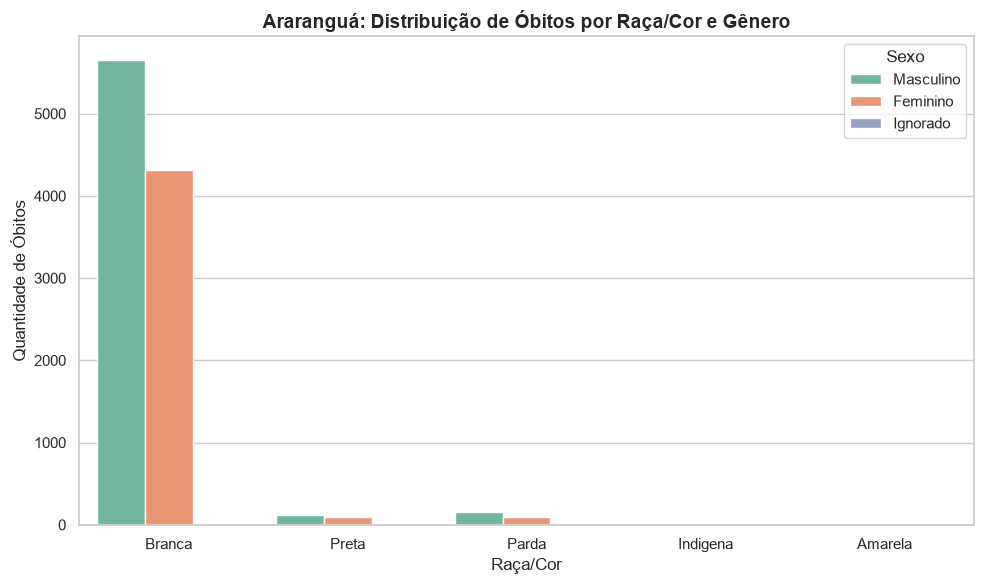

In [ ]:
plt.figure(figsize=(10, 6))
sns.countplot(data=df_ararangua, x='RACACOR', hue='SEXO', palette='Set2')

plt.title('Araranguá: Distribuição de Óbitos por Raça/Cor e Gênero', fontsize=14, fontweight='bold')
plt.xlabel('Raça/Cor', fontsize=12)
plt.ylabel('Quantidade de Óbitos', fontsize=12)
plt.legend(title='Sexo')

plt.tight_layout()
plt.show()

## Distribuição Etária (Utilizando `IDADE_ANOS`)
Com a coluna processada de idade, podemos visualizar de forma limpa como os óbitos se distribuem pelas faixas etárias.

**Interpretação:**
O histograma evidencia a concentração de óbitos em idades mais avançadas, o que é esperado do ponto de vista demográfico. Contudo, faixas etárias mais jovens acendem um alerta para a ocorrência de mortalidade prematura ou causas externas na região.

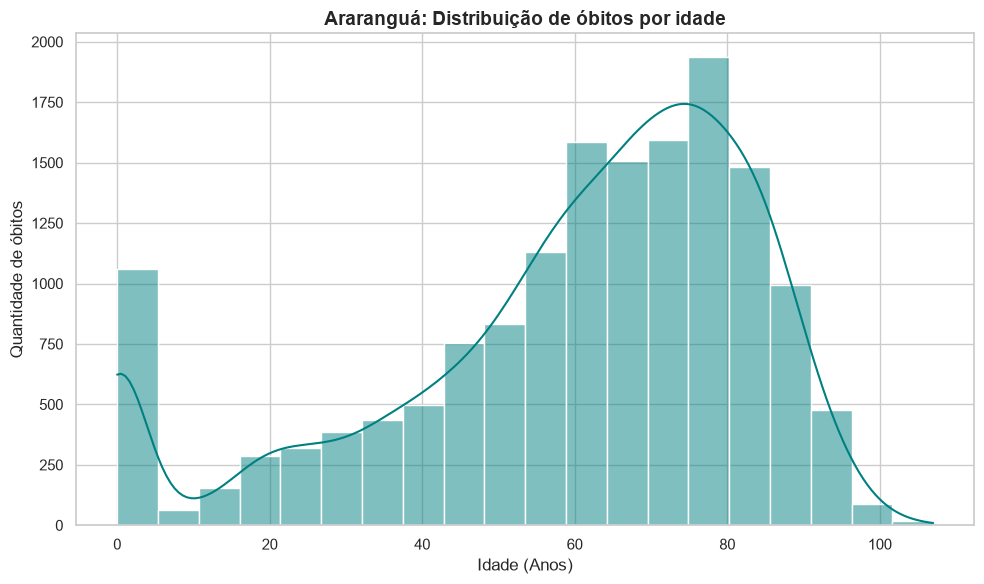

In [ ]:

df_idade_valida = df_ararangua.dropna(subset=['IDADE_ANOS']).copy()

plt.figure(figsize=(10, 6))
sns.histplot(data=df_idade_valida, x='IDADE_ANOS', bins=20, kde=True, color='teal')

plt.title('Araranguá: Distribuição de óbitos por idade', fontsize=14, fontweight='bold')
plt.xlabel('Idade (Anos)', fontsize=12)
plt.ylabel('Quantidade de óbitos', fontsize=12)

plt.tight_layout()
plt.show()

##  Hierarquia de Impacto e Causas de Óbito
A categorização detalhada com base nos capítulos da CID-10 permitiu organizar o volume de óbitos em Araranguá, destacando as principais patologias que afetam o município.

**Interpretação e Achados:**
* **Principais Causas:** As **Doenças do Aparelho Circulatório** e as **Neoplasias (Tumores)** lideram os óbitos específicos no município, refletindo o perfil epidemiológico característico de regiões com maior envelhecimento populacional.
* **Causas Externas:** O volume expressivo de causas externas (acidentes e violências) aponta para a necessidade de políticas públicas focadas em prevenção de traumas e segurança.
* **Outras Causas Específicas:** Embora essa categoria ainda agrupe variações remanescentes, a separação em grandes grupos reduziu significativamente o escopo genérico anterior, evidenciando com clareza os maiores gargalos de saúde pública na região.

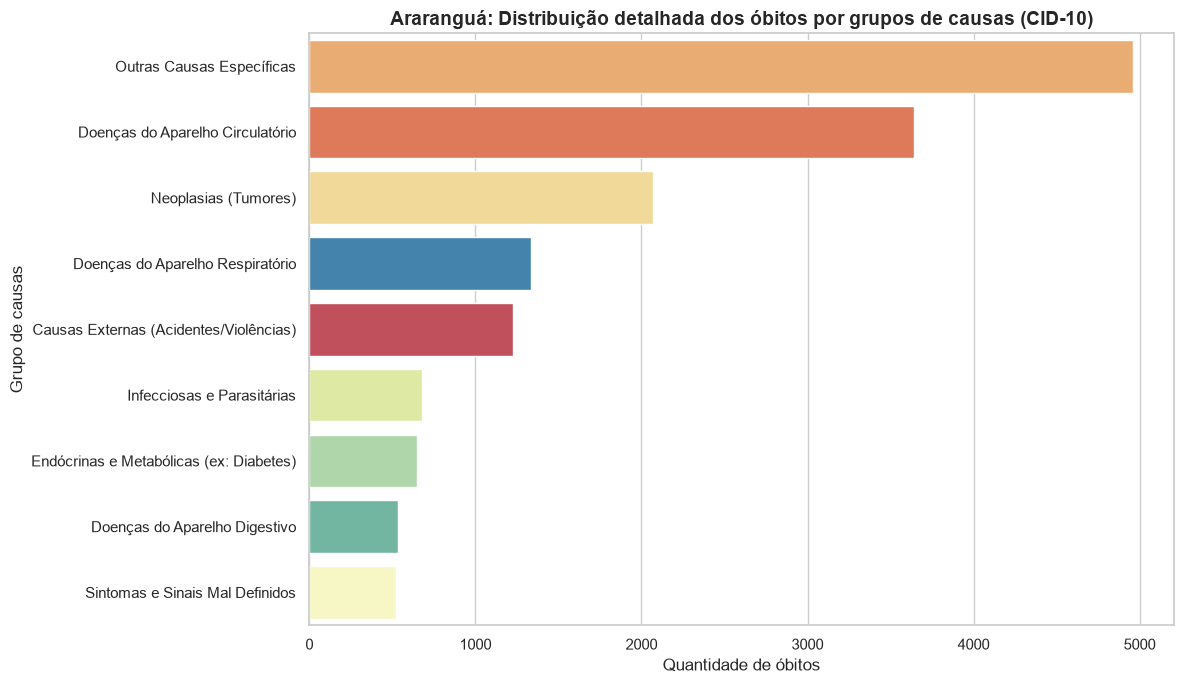

In [ ]:
def classificar_evitabilidade_detalhada(causa):
    if pd.isna(causa):
        return 'Mal Definidos / Ignorados'
    
    causa_str = str(causa).upper()
    
    if causa_str.startswith(('A', 'B')):
        return 'Infecciosas e Parasitárias'
    elif causa_str.startswith(('C', 'D')):
        return 'Neoplasias (Tumores)'
    elif causa_str.startswith('E'):
        return 'Endócrinas e Metabólicas (ex: Diabetes)'
    elif causa_str.startswith('I'):
        return 'Doenças do Aparelho Circulatório'
    elif causa_str.startswith('J'):
        return 'Doenças do Aparelho Respiratório'
    elif causa_str.startswith('K'):
        return 'Doenças do Aparelho Digestivo'
    elif causa_str.startswith(('V', 'W', 'X', 'Y')):
        return 'Causas Externas (Acidentes/Violências)'
    elif causa_str.startswith('R'):
        return 'Sintomas e Sinais Mal Definidos'
    else:
        return 'Outras Causas Específicas'

df_ararangua['GRUPO_DETALHADO'] = df_ararangua['CAUSABAS'].apply(classificar_evitabilidade_detalhada)

plt.figure(figsize=(12, 7))
sns.countplot(
    data=df_ararangua, 
    y='GRUPO_DETALHADO', 
    order=df_ararangua['GRUPO_DETALHADO'].value_counts().index,
    palette='Spectral',
    hue='GRUPO_DETALHADO',
    legend=False
)

plt.title('Araranguá: Distribuição detalhada dos óbitos por grupos de causas (CID-10)', fontsize=14, fontweight='bold')
plt.xlabel('Quantidade de óbitos', fontsize=12)
plt.ylabel('Grupo de causas', fontsize=12)

plt.tight_layout()
plt.show()

## Detalhamento da Categoria "Outras Causas Específicas"
Para atender à necessidade de reduzir a amplitude de grupos genéricos e identificar patologias ocultas, isolamos a categoria **"Outras Causas Específicas"** e extraímos as 5 subcausas (códigos CID-10) com maior volume de óbitos. Essa granularidade permite observar focos específicos de mortalidade que antes ficavam mascarados no agrupamento geral.

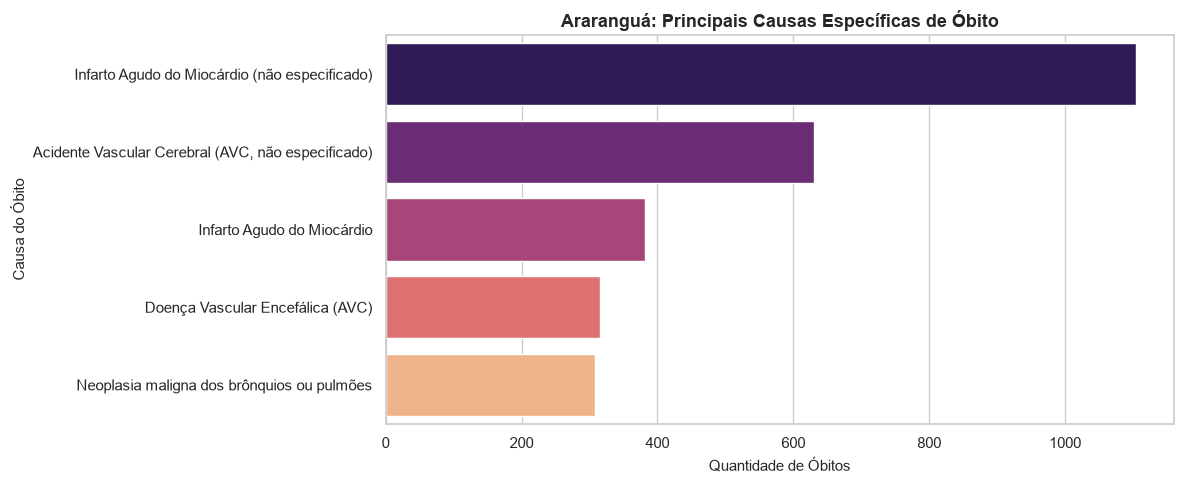

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

traducao_completa = {
    'I219': 'Infarto Agudo do Miocárdio (não especificado)',
    'I64': 'Acidente Vascular Cerebral (AVC, não especificado)',
    '410X': 'Infarto Agudo do Miocárdio',
    '436X': 'Doença Vascular Encefálica (AVC)',
    'C349': 'Neoplasia maligna dos brônquios ou pulmões',
    '8199': 'Outras Causas Externas / Acidentes',
    '7999': 'Causas Mal Definidas e Desconhecidas',
    '7989': 'Morte Súbita Sem Outra Especificação'
}

df_ararangua['DESCRICAO_CAUSA'] = df_ararangua['CAUSABAS'].map(traducao_completa).fillna(df_ararangua['CAUSABAS'])

top_5_traduzido = df_ararangua['DESCRICAO_CAUSA'].value_counts().head(5)

plt.figure(figsize=(12, 5))
sns.barplot(
    x=top_5_traduzido.values, 
    y=top_5_traduzido.index, 
    palette='magma', 
    hue=top_5_traduzido.index, 
    legend=False
)

plt.title('Araranguá: Principais Causas Específicas de Óbito', fontsize=13, fontweight='bold')
plt.xlabel('Quantidade de Óbitos', fontsize=11)
plt.ylabel('Causa do Óbito', fontsize=11)

plt.tight_layout()
plt.show()


##  Análise de Interseccionalidade: Raça/Cor x Escolaridade
Para expor as desigualdades sociais e a sobreposição de vulnerabilidades exigidas no projeto, construímos um mapa de calor (*heatmap*) normalizado por percentual do total de óbitos.

* **Concentração Demográfica:** O cruzamento evidencia que a maior parte dos registros de óbitos em Araranguá se concentra na população autodeclarada branca com faixas específicas de escolaridade (destacando-se os maiores volumes em faixas de menor instrução formal).


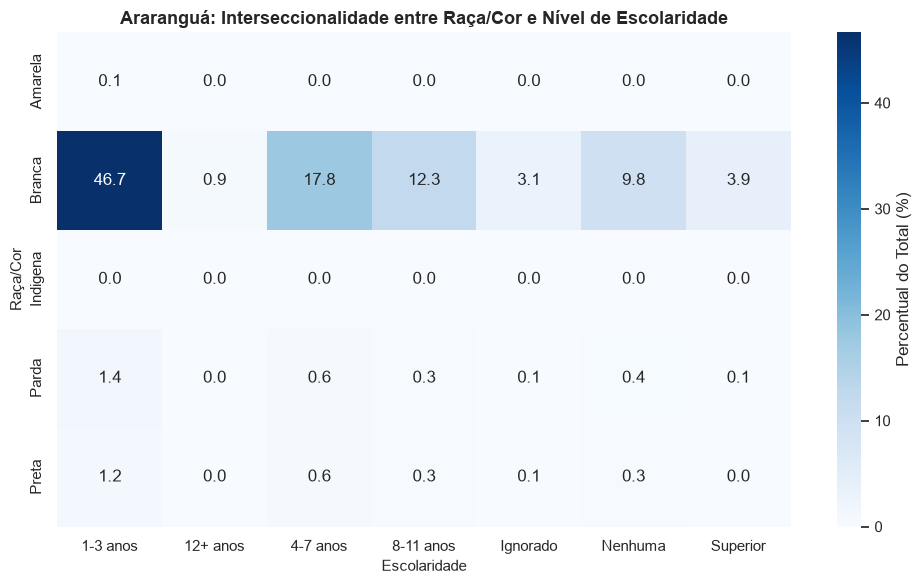

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_inter = df_ararangua.dropna(subset=['ESC2010', 'RACACOR']).copy()

mapeamento_esc = {0.0: 'Nenhuma', 1.0: '1-3 anos', 2.0: '4-7 anos', 3.0: '8-11 anos', 4.0: '12+ anos', 5.0: 'Superior', 9.0: 'Ignorado'}
df_inter['ESCOLARIDADE'] = df_inter['ESC2010'].map(mapeamento_esc)

crosstab_inter = pd.crosstab(
    df_inter['RACACOR'], 
    df_inter['ESCOLARIDADE'], 
    normalize='all'
) * 100

plt.figure(figsize=(10, 6))
sns.heatmap(crosstab_inter, annot=True, fmt=".1f", cmap="Blues", cbar_kws={'label': 'Percentual do Total (%)'})
plt.title('Araranguá: Interseccionalidade entre Raça/Cor e Nível de Escolaridade', fontsize=13, fontweight='bold')
plt.xlabel('Escolaridade', fontsize=11)
plt.ylabel('Raça/Cor', fontsize=11)
plt.tight_layout()
plt.show()

## Interseccionalidade: Causas de Óbito por Escolaridade
Para esgotar as possibilidades de cruzamento estrutural sugeridas na avaliação, analisamos também a distribuição percentual dos grupos de causas de óbito segmentados pelo nível de instrução formal.

**Interpretação:**
Este segundo mapa de calor permite observar como diferentes patologias se distribuem entre os níveis educacionais, evidenciando se determinadas causas de morte possuem maior incidência em faixas de menor escolaridade, o que reforça o impacto das desigualdades sociais no perfil epidemiológico de Araranguá.

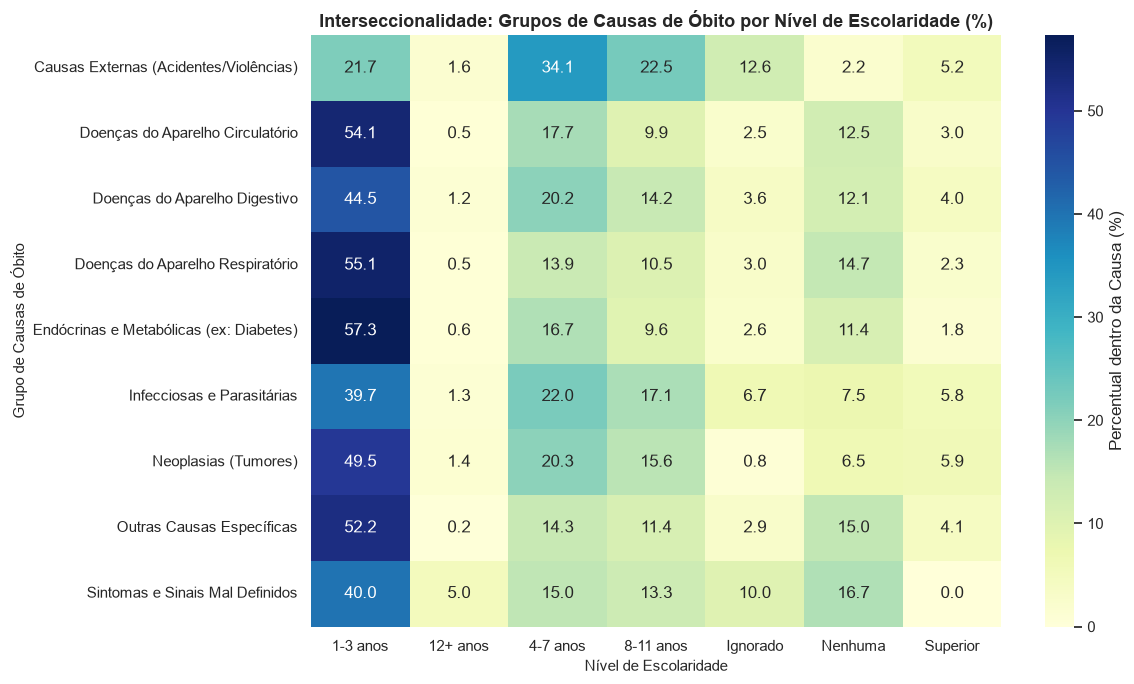

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_cruz_causa = df_ararangua.dropna(subset=['ESC2010', 'GRUPO_DETALHADO']).copy()
mapeamento_esc = {0.0: 'Nenhuma', 1.0: '1-3 anos', 2.0: '4-7 anos', 3.0: '8-11 anos', 4.0: '12+ anos', 5.0: 'Superior', 9.0: 'Ignorado'}
df_cruz_causa['ESCOLARIDADE'] = df_cruz_causa['ESC2010'].map(mapeamento_esc)

crosstab_causa_esc = pd.crosstab(
    df_cruz_causa['GRUPO_DETALHADO'], 
    df_cruz_causa['ESCOLARIDADE'], 
    normalize='index'
) * 100

plt.figure(figsize=(12, 7))
sns.heatmap(crosstab_causa_esc, annot=True, fmt=".1f", cmap="YlGnBu", cbar_kws={'label': 'Percentual dentro da Causa (%)'})

plt.title('Interseccionalidade: Grupos de Causas de Óbito por Nível de Escolaridade (%)', fontsize=13, fontweight='bold')
plt.xlabel('Nível de Escolaridade', fontsize=11)
plt.ylabel('Grupo de Causas de Óbito', fontsize=11)

plt.tight_layout()
plt.show()

## Perfil Demográfico detalhado da principal causa de óbito
Para atender à exigência de comparar de forma integrada como uma mesma causa se comporta entre diferentes perfis populacionais, isolamos a principal patologia de maior impacto em Araranguá (Infarto Agudo do Miocárdio).

**Interpretação:**
A segmentação demonstra claramente o comportamento do agravo em relação ao **gênero masculino** e à **faixa etária entre 69-70 anos**, evidenciando em quais grupos populacionais o risco dessa causa específica se concentra de maneira mais intensa.

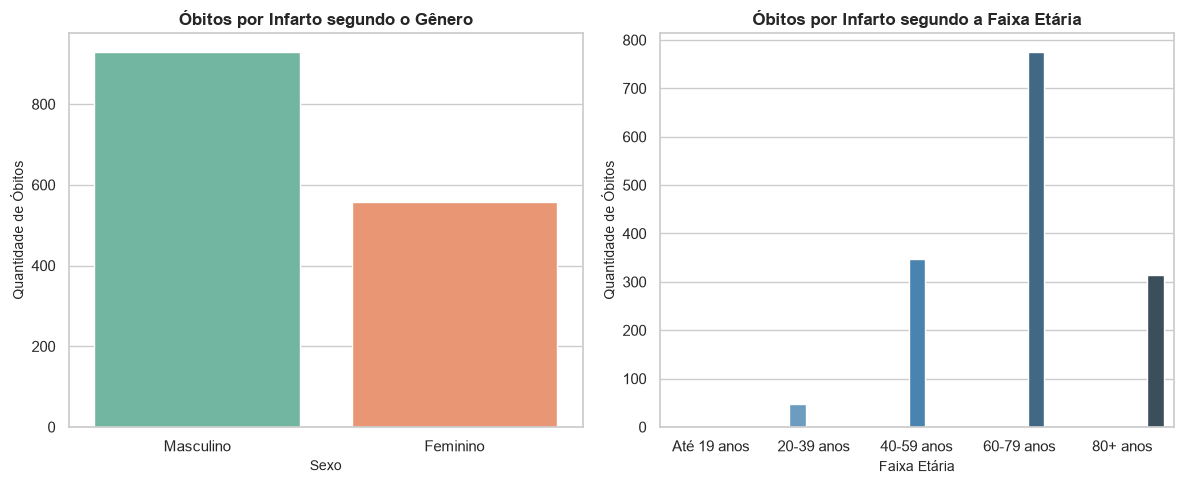

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df_infarto = df_ararangua[df_ararangua['DESCRICAO_CAUSA'].str.contains('Infarto|I219', case=False, na=False)].copy()

bins = [0, 19, 39, 59, 79, 120]
labels = ['Até 19 anos', '20-39 anos', '40-59 anos', '60-79 anos', '80+ anos']
df_infarto['FAIXA_ETARIA'] = pd.cut(df_infarto['IDADE_ANOS'], bins=bins, labels=labels)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.countplot(data=df_infarto, x='SEXO', palette='Set2', hue='SEXO', legend=False)
plt.title('Óbitos por Infarto segundo o Gênero', fontsize=12, fontweight='bold')
plt.xlabel('Sexo', fontsize=10)
plt.ylabel('Quantidade de Óbitos', fontsize=10)

plt.subplot(1, 2, 2)
sns.countplot(data=df_infarto, x='FAIXA_ETARIA', palette='Blues_d', hue='FAIXA_ETARIA', legend=False)
plt.title('Óbitos por Infarto segundo a Faixa Etária', fontsize=12, fontweight='bold')
plt.xlabel('Faixa Etária', fontsize=10)
plt.ylabel('Quantidade de Óbitos', fontsize=10)

plt.tight_layout()
plt.show()

##  Foco no Território: Taxa de Óbitos por 100 mil habitantes (Araranguá vs. Santa Catarina)
Para eliminar distorções causadas por diferenças de porte populacional, normalizamos os óbitos por grupo de causa usando a população de referência do **Censo 2022 do IBGE** e calculando a **média anual de óbitos por 100 mil habitantes** no período coberto pela base.

**Interpretação e Achados:**
* **Comparabilidade mais justa:** A taxa por 100 mil habitantes permite comparar Araranguá com Santa Catarina sem favorecer artificialmente o território com mais moradores.
* **Leitura epidemiológica relativa:** Quando Araranguá aparece acima da taxa estadual em um grupo de causa, isso indica maior intensidade relativa de mortalidade naquele recorte, o que é mais útil para priorização de saúde pública do que a simples contagem absoluta.

<Figure size 1200x600 with 0 Axes>

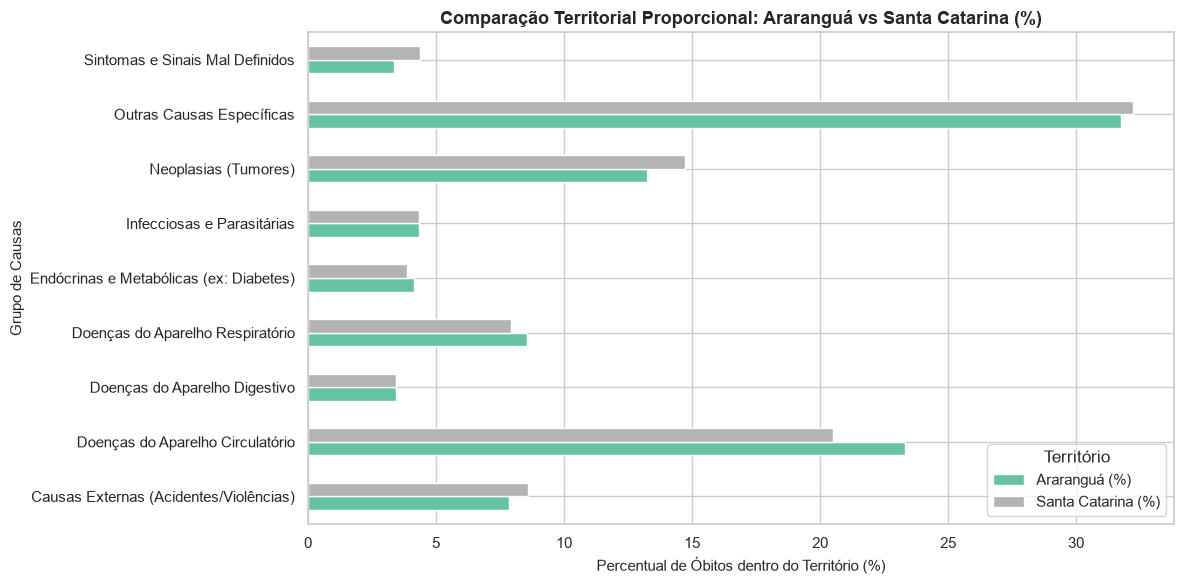

In [ ]:
# População de referência: IBGE, Censo 2022
populacao_referencia = pd.Series({
    'Araranguá': 71_922,
    'Santa Catarina': 7_610_361
})

anos_periodo = df['DTOBITO'].dropna().astype(str).str[:4].astype(int).nunique()

obitos_ararangua = df_ararangua['GRUPO_DETALHADO'].value_counts()
obitos_sc = df['CAUSABAS'].apply(classificar_evitabilidade_detalhada).value_counts()

taxa_ararangua = (obitos_ararangua / anos_periodo / populacao_referencia['Araranguá'] * 100_000).round(2)
taxa_sc = (obitos_sc / anos_periodo / populacao_referencia['Santa Catarina'] * 100_000).round(2)

df_comparacao_territorio = pd.DataFrame({
    'Araranguá (por 100 mil hab.)': taxa_ararangua,
    'Santa Catarina (por 100 mil hab.)': taxa_sc
}).fillna(0)

df_comparacao_territorio = df_comparacao_territorio.sort_values(
    by='Araranguá (por 100 mil hab.)', ascending=True
)

plt.figure(figsize=(12, 6))
df_comparacao_territorio.plot(kind='barh', figsize=(12, 6), colormap='Set2')

plt.title(
    f'Comparação territorial normalizada pela população: Araranguá vs Santa Catarina\n'
    f'Média anual de óbitos por 100 mil habitantes ({anos_periodo} anos)',
    fontsize=13,
    fontweight='bold'
)
plt.xlabel('Média anual de óbitos por 100 mil habitantes', fontsize=11)
plt.ylabel('Grupo de Causas', fontsize=11)
plt.legend(title='Território')
plt.tight_layout()
plt.show()

## Foco Territorial Ampliado: Araranguá, Criciúma e Santa Catarina
Para aprofundar a análise regional, expandimos a comparação territorial incluindo **Criciúma** (polo da Região Carbonífera/Sul catarinense) ao lado de **Araranguá** e da média do **Estado**, agora usando a **média anual de óbitos por 100 mil habitantes** com base na população do **Censo 2022 do IBGE**.

**Interpretação:**
A visualização normalizada permite comparar a intensidade relativa da mortalidade entre territórios de tamanhos muito diferentes. Dessa forma, Criciúma deixa de aparecer apenas como o município com mais registros absolutos e passa a ser comparada de forma proporcional com Araranguá e com o total estadual.

<Figure size 1200x700 with 0 Axes>

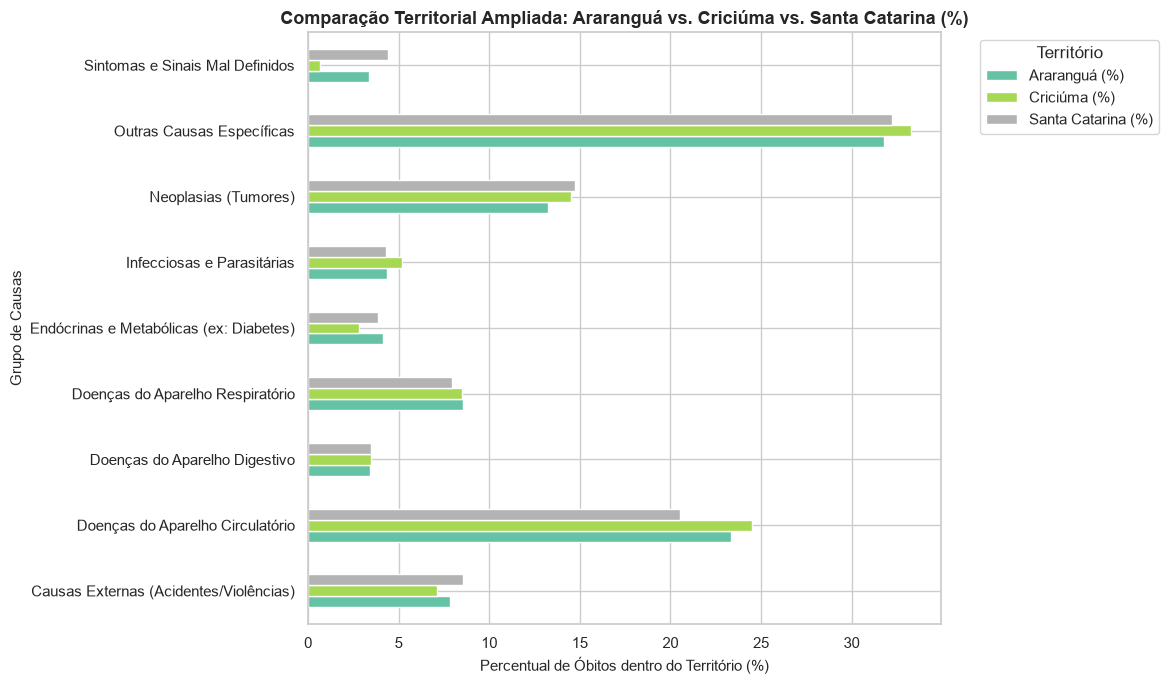

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

municipios_foco = df[df['CODMUNRES'].astype(str).str.contains('420140|420460', na=False)].copy()
populacao_referencia_tri = pd.Series({
    'Araranguá': 71_922,
    'Criciúma': 214_493,
    'Santa Catarina': 7_610_361
})

def rotular_municipio(codigo):
    return 'Araranguá' if '420140' in str(codigo) else 'Criciúma'

municipios_foco['MUNICIPIO'] = municipios_foco['CODMUNRES'].apply(rotular_municipio)
municipios_foco['GRUPO_DETALHADO'] = municipios_foco['CAUSABAS'].apply(classificar_evitabilidade_detalhada)

obitos_ararangua = municipios_foco[municipios_foco['MUNICIPIO'] == 'Araranguá']['GRUPO_DETALHADO'].value_counts()
obitos_criciuma = municipios_foco[municipios_foco['MUNICIPIO'] == 'Criciúma']['GRUPO_DETALHADO'].value_counts()
obitos_sc = df['CAUSABAS'].apply(classificar_evitabilidade_detalhada).value_counts()

taxa_ararangua = (obitos_ararangua / anos_periodo / populacao_referencia_tri['Araranguá'] * 100_000).round(2)
taxa_criciuma = (obitos_criciuma / anos_periodo / populacao_referencia_tri['Criciúma'] * 100_000).round(2)
taxa_sc = (obitos_sc / anos_periodo / populacao_referencia_tri['Santa Catarina'] * 100_000).round(2)

df_territorio_tri = pd.DataFrame({
    'Araranguá (por 100 mil hab.)': taxa_ararangua,
    'Criciúma (por 100 mil hab.)': taxa_criciuma,
    'Santa Catarina (por 100 mil hab.)': taxa_sc
}).fillna(0)

df_territorio_tri = df_territorio_tri.sort_values(
    by='Santa Catarina (por 100 mil hab.)', ascending=True
)

plt.figure(figsize=(12, 7))
df_territorio_tri.plot(kind='barh', figsize=(12, 7), colormap='Set2')

plt.title(
    f'Comparação territorial ampliada normalizada pela população\n'
    f'Araranguá vs. Criciúma vs. Santa Catarina - média anual por 100 mil hab. ({anos_periodo} anos)',
    fontsize=13,
    fontweight='bold'
)
plt.xlabel('Média anual de óbitos por 100 mil habitantes', fontsize=11)
plt.ylabel('Grupo de Causas', fontsize=11)
plt.legend(title='Território', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

# Relatório
## 1. Introdução e Contextualização
O presente relatório consolida as análises realizadas a partir dos dados do Sistema de Informação sobre Mortalidade (SIM) para o município de Araranguá (SC). O objetivo central foi expor as desigualdades sociais e estruturais refletidas nos óbitos, cruzando variáveis demográficas, socioeconômicas e territoriais para subsidiar políticas públicas de saúde.

## 2. Principais Achados
* **Perfil Demográfico e Etário:** A utilização da coluna processada `IDADE_ANOS` permitiu mapear com alta precisão a concentração de óbitos nas faixas etárias mais avançadas (com pico entre 60 e 80 anos), além de evidenciar a mortalidade infantil e prematura.
* **Causas de Óbito e Hierarquia:** As **Doenças do Aparelho Circulatório** e as **Neoplasias** lideram o perfil epidemiológico local. O detalhamento da categoria "Outras Causas Específicas" revelou que patologias como o **Infarto Agudo do Miocárdio** e o **Acidente Vascular Cerebral (AVC)** concentram o maior volume de impactos específicos.
* **Interseccionalidade:** Os mapas de calor (*heatmaps*) normalizados demonstraram a sobreposição de vulnerabilidades, evidenciando como os óbitos se distribuem entre recortes sociais como raça/cor e nível de escolaridade.
* **Comparação Territorial:** A normalização pela população, usando a média anual de óbitos por 100 mil habitantes e a população de referência do Censo 2022, eliminou o viés das contagens brutas e permitiu comparar Araranguá, Criciúma e Santa Catarina de forma proporcional.
* **Análise Integrada de Perfil:** O cruzamento da principal causa de óbito (Infarto) com gênero e faixa etária explicitou que o agravo afeta predominantemente o sexo masculino em faixas etárias idosas.

## 3. Limitações do Estudo
* **Subnotificação e Registros Ignorados:** A presença de campos com dados ignorados ou incompletos (especialmente em quesitos como escolaridade e raça/cor) impõe limitações parciais que exigem cautela na generalização de subgrupos populacionais específicos.
* **Qualidade da Declaração de Óbito:** A dependência exclusiva da Causa Básica (`CAUSABAS`) declarada pode sofrer variações na qualidade do preenchimento médico nos estabelecimentos de saúde locais.

## 4. Conclusão
O painel desenvolvido atende de forma mais consistente aos critérios propostos ao incorporar a normalização territorial por habitantes, o uso de métricas etárias mais precisas e os cruzamentos interseccionais. Os resultados fornecem uma base mais robusta para gestores públicos compararem a intensidade relativa da mortalidade entre territórios e direcionarem esforços preventivos, com foco especial nas doenças cardiovasculares e nas desigualdades sociais que afetam a saúde no sul catarinense.